# 4. Regression — Πρόβλεψη του SalePrice

Σε αυτό το notebook απαντάμε στο Βήμα 3(b). Προβλέπουμε την τιμή πώλησης μιας
κατοικίας, δηλαδή το **SalePrice**, με δύο νευρωνικά δίκτυα TensorFlow/Keras.
Εκπαιδεύουμε το πρώτο από την αρχή. Για το δεύτερο μεταφέρουμε επίπεδα που έχουμε
πρώτα εκπαιδεύσει σε ένα συγγενικό πρόβλημα: την πρόβλεψη του HouseStyle.

Συγκρίνουμε τα δύο μοντέλα με **MAE, MAPE και RMSE** και εξετάζουμε γραφήματα
εκπαίδευσης και προβλέψεων. Στο classification προβλέπαμε κατηγορία· εδώ
προβλέπουμε έναν αριθμό, την τιμή του σπιτιού σε ευρώ. Μετατρέπουμε τις αρχικές τιμές του dataset
με τη σταθερή ενδεικτική ισοτιμία **1 USD = 0,90 EUR**, όχι με τρέχουσα ή
ιστορική ισοτιμία της ημερομηνίας πώλησης.

### 1. Φορτώνουμε τις βιβλιοθήκες

Χρησιμοποιούμε pandas για τα δεδομένα, numpy για αριθμητικές πράξεις και
matplotlib για γραφήματα. Με το TensorFlow/Keras δημιουργούμε και εκπαιδεύουμε
τα νευρωνικά δίκτυα. Από το Scikit-Learn παίρνουμε εργαλεία για τον διαχωρισμό,
το scaling, τις ετικέτες HouseStyle και τις μετρικές.

Ορίζουμε έναν σταθερό σπόρο τυχαιότητας με το set_random_seed(42), ώστε να μπορούμε
να επαναλάβουμε το πείραμα. Μπορεί να έχουμε μικρές διαφορές ανάλογα με τις εκδόσεις
βιβλιοθηκών και τον υπολογιστή. Πριν από την πρώτη εκτέλεση εγκαθιστούμε στο
περιβάλλον Python του notebook τις βιβλιοθήκες που περιγράφουμε στο libraries.txt, στον ίδιο φάκελο με το notebook.
Για εγκατάσταση των συγκεκριμένων εκδόσεων μπορούμε να χρησιμοποιήσουμε το requirements.txt.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error

keras.utils.set_random_seed(42)

2026-09-10 15:33:56.298705: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-09-10 15:33:56.363181: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-09-10 15:33:58.509243: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### 2. Διαβάζουμε τα δεδομένα

Διαβάζουμε το αρχικό train.csv, όπου γνωρίζουμε το SalePrice. Όπως στο classification,
ξεκινάμε από το αρχικό αρχείο για να υπολογίσουμε το scaling μετά τον διαχωρισμό,
μόνο από τις κατοικίες εκπαίδευσης. Αξιοποιούμε την εξερεύνηση του preprocessing
για να επιλέξουμε τις εισόδους μας.

Δημιουργούμε τον φάκελο results/regression για τα γραφήματα και τις μετρικές.
Εκτελούμε το notebook από τον φάκελο notebooks, ώστε οι σχετικές διαδρομές να
οδηγούν στα σωστά αρχεία. Δεν χρησιμοποιούμε το test.csv του Kaggle για μέτρηση
σφαλμάτων, επειδή εκεί δεν γνωρίζουμε τις πραγματικές τιμές SalePrice.

In [2]:
data = pd.read_csv(
    "../data/house-prices/train.csv",
    keep_default_na=False, na_values=["NA", ""]
)
results_dir = Path("../results/regression")
results_dir.mkdir(parents=True, exist_ok=True)

### 3. Επιλέγουμε χαρακτηριστικά και στόχο

Χρησιμοποιούμε τις επιφάνειες κατοικίας, ορόφων, υπογείου, γκαράζ και οικοπέδου,
το πλήθος δωματίων και μπάνιων και το έτος κατασκευής. Προσθέτουμε τη συνολική
ποιότητα (OverallQual), τη συνολική κατάσταση (OverallCond), το έτος ανακαίνισης
(YearRemodAdd) και τη χωρητικότητα γκαράζ (GarageCars), επειδή μπορεί να βοηθούν
στην εξήγηση της τιμής. Κρατάμε αυτές τις διατεταγμένες βαθμολογίες ως αριθμούς,
ως απλή επιλογή μοντελοποίησης.

Προβλέπουμε το SalePrice από αυτές τις 14 στήλες. Δεν δίνουμε στα μοντέλα το
SalePrice, το Id ή το HouseStyle ως χαρακτηριστικά εισόδου. Χρησιμοποιούμε
το HouseStyle μόνο ως στόχο της ξεχωριστής προεκπαίδευσης στο Βήμα 8.

Ελέγχουμε ότι οι επιλεγμένες στήλες και οι δύο στόχοι δεν έχουν κενά. Στο συγκεκριμένο
train δεν βρίσκουμε κενά σε αυτές τις στήλες, οπότε δεν χρειάζεται συμπλήρωση.
Δεν κάνουμε one-hot encoding στις εισόδους, αφού τις έχουμε επιλέξει αριθμητικές.
Κρατάμε τις ακραίες τιμές, ώστε να αξιολογήσουμε τα μοντέλα και σε ασυνήθιστα σπίτια.

In [3]:
features = [
    "GrLivArea", "1stFlrSF", "2ndFlrSF", "TotalBsmtSF", "GarageArea",
    "LotArea", "TotRmsAbvGrd", "FullBath", "HalfBath", "YearBuilt",
    "OverallQual", "OverallCond", "YearRemodAdd", "GarageCars"
]

print("Κενά στις εισόδους:", data[features].isna().sum().sum())
print("Κενά στο SalePrice:", data["SalePrice"].isna().sum())
print("Κενά στο HouseStyle:", data["HouseStyle"].isna().sum())

Κενά στις εισόδους: 0
Κενά στο SalePrice: 0
Κενά στο HouseStyle: 0


### 4. Χωρίζουμε σε train, validation και test

Κρατάμε πρώτα το 20% ως test για την τελική αξιολόγηση. Από το υπόλοιπο 80%
κρατάμε το ένα τέταρτο ως validation. Έτσι έχουμε περίπου **60% train, 20%
validation και 20% test**.

Με το train εκπαιδεύουμε τα βάρη. Με το validation παρακολουθούμε πότε σταματά
να βελτιώνεται το μοντέλο και επιλέγουμε την καλύτερη εποχή εκπαίδευσης.
Χρησιμοποιούμε το test μόνο στο τέλος για να μετρήσουμε την επίδοση.

Με το stratify κρατάμε περίπου τις ίδιες αναλογίες HouseStyle στα τρία μέρη,
επειδή θα χρησιμοποιήσουμε αυτή την κατηγορία στην προεκπαίδευση. Με τον ίδιο
διαχωρισμό συγκρίνουμε δίκαια τα δύο regression μοντέλα. Δεν εκπαιδεύουμε ούτε
το βοηθητικό μοντέλο HouseStyle πάνω στις κατοικίες του test.

In [4]:
train_data, test_data = train_test_split(
    data, test_size=0.20, random_state=42, stratify=data["HouseStyle"]
)
train_data, val_data = train_test_split(
    train_data, test_size=0.25, random_state=42, stratify=train_data["HouseStyle"]
)

print("Εκπαίδευση:", len(train_data))
print("Validation:", len(val_data))
print("Τελική αξιολόγηση:", len(test_data))

Εκπαίδευση: 876
Validation: 292
Τελική αξιολόγηση: 292


### 5. Κάνουμε scaling και μετατρέπουμε το SalePrice σε ευρώ

Υπολογίζουμε με τον StandardScaler τον μέσο όρο και την τυπική απόκλιση κάθε
εισόδου μόνο στο train. Μετασχηματίζουμε validation και test με τις ίδιες τιμές.
Έτσι φέρνουμε τις εισόδους σε συγκρίσιμες κλίμακες χωρίς πληροφορία από το test.

Το αρχικό SalePrice δίνεται σε ευρώ. Πολλαπλασιάζουμε τις τιμές με
**usd_to_eur = 0.90**, δηλαδή χρησιμοποιούμε σταθερά **1 δολάριο = 0,90 ευρώ**.
Για παράδειγμα, μετατρέπουμε 200.000 ευρώ σε 180.000 ευρώ. Κάνουμε μόνο
αλλαγή νομίσματος για την παρουσίαση του πειράματος, χωρίς προσαρμογή πληθωρισμού
ή χρήση ιστορικής ισοτιμίας. Δεν αλλάζουμε τα αρχικά CSV του dataset.

Για την εκπαίδευση διαιρούμε τις τιμές σε ευρώ με το σταθερό
**price_scale = 100000 * 0.90 = 90000**. Έτσι αναπαριστούμε τα 180.000 ευρώ
ως 2 και κρατάμε την ίδια αριθμητική κλίμακα εκπαίδευσης με πριν. Στο τέλος
πολλαπλασιάζουμε τις προβλέψεις με 90.000 και παίρνουμε ποσά σε ευρώ.
Κρατάμε το y_test ήδη σε ευρώ για να υπολογίσουμε σωστά τα σφάλματα.

Με το to_numpy μετατρέπουμε τις τιμές σε αριθμητικούς πίνακες για το Keras,
χωρίς να τους εμφανίζουμε στην έξοδο.

In [5]:
scaler = StandardScaler()
X_train = scaler.fit_transform(train_data[features])
X_val = scaler.transform(val_data[features])
X_test = scaler.transform(test_data[features])

usd_to_eur = 0.90  # Σταθερή ενδεικτική ισοτιμία
price_scale = 100000 * usd_to_eur
y_train = train_data["SalePrice"].to_numpy() * usd_to_eur / price_scale
y_val = val_data["SalePrice"].to_numpy() * usd_to_eur / price_scale
y_test = test_data["SalePrice"].to_numpy() * usd_to_eur

### 6. Φτιάχνουμε το δικό μας νευρωνικό δίκτυο

Χρησιμοποιούμε Sequential για να βάλουμε τα επίπεδα στη σειρά. Δίνουμε 14 εισόδους
και βάζουμε δύο κρυφά Dense επίπεδα, με 64 και 32 νευρώνες. Με τη ReLU επιτρέπουμε
στο δίκτυο να μάθει μη γραμμικές σχέσεις ανάμεσα στα χαρακτηριστικά και την τιμή.

Στο τελευταίο Dense βάζουμε έναν νευρώνα, επειδή προβλέπουμε έναν αριθμό. Δεν
βάζουμε softmax, γιατί δεν προβλέπουμε κατηγορία. Ξεκινάμε όλα τα βάρη από τυχαίες
τιμές και τα μαθαίνουμε από το SalePrice των κατοικιών εκπαίδευσης.

Με το compile επιλέγουμε Adam για την ενημέρωση των βαρών και MSE ως συνάρτηση
σφάλματος. Με το MSE υπολογίζουμε τον μέσο όρο των τετραγώνων των σφαλμάτων,
οπότε δίνουμε μεγαλύτερη βαρύτητα στα μεγάλα λάθη.

In [6]:
direct_model = keras.Sequential([
    keras.Input(shape=(len(features),)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])
direct_model.compile(optimizer="adam", loss="mse")

### 7. Εκπαιδεύουμε το πρώτο μοντέλο

Με το fit εκπαιδεύουμε για έως 200 εποχές. Σε κάθε εποχή περνάμε από τα δεδομένα
εκπαίδευσης σε ομάδες των 32 κατοικιών. Παρακολουθούμε το val_loss, δηλαδή το
σφάλμα στο validation που δεν χρησιμοποιούμε για ενημέρωση των βαρών.

Με το EarlyStopping σταματάμε αν το val_loss δεν βελτιωθεί για 20 εποχές.
Με το restore_best_weights=True κρατάμε τα βάρη της καλύτερης εποχής, όχι
απαραίτητα της τελευταίας. Με το verbose=0 αποφεύγουμε μεγάλες εκτυπώσεις και
κρατάμε το history για να σχεδιάσουμε τις καμπύλες εκπαίδευσης.

In [7]:
direct_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=20, restore_best_weights=True
)
direct_history = direct_model.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=200, batch_size=32, callbacks=[direct_stop], verbose=0
)
print("Εποχές πρώτου μοντέλου:", len(direct_history.history["loss"]))

Εποχές πρώτου μοντέλου: 57


### 8. Προεκπαιδεύουμε μια βάση για το transfer learning

Πριν φτιάξουμε το δεύτερο regression μοντέλο, εκπαιδεύουμε ένα μικρό βοηθητικό
δίκτυο να προβλέπει **HouseStyle**. Χρησιμοποιούμε τις ίδιες 14 εισόδους και
ακριβώς τις ίδιες κατοικίες train και validation. Επιλέγουμε αυτό το συγγενικό
πρόβλημα επειδή το στυλ και η τιμή σχετίζονται με χαρακτηριστικά της κατοικίας.
Εξετάζουμε πειραματικά αν όσα μαθαίνουμε για το στυλ βοηθούν στην τιμή.

Με το LabelEncoder αντιστοιχίζουμε τα ονόματα κατηγοριών σε ακέραιους 0 έως 7.
Δεν θεωρούμε ότι αυτοί οι αριθμοί έχουν σειρά ή απόσταση μεταξύ τους: τους
χρησιμοποιούμε μόνο ως ετικέτες για τη sparse_categorical_crossentropy.

Ονομάζουμε base τα δύο κρυφά επίπεδα που θα μεταφέρουμε. Προσθέτουμε προσωρινά
έξοδο με έναν νευρώνα ανά HouseStyle και softmax για πιθανότητες κατηγοριών.
Εκπαιδεύουμε με early stopping στο validation και μέγιστο 120 εποχές.

Εδώ δημιουργούμε εμείς την προεκπαιδευμένη βάση, αντί να κατεβάσουμε ένα έτοιμο
μοντέλο άλλου dataset. Μεταφέρουμε γνώση από διαφορετικό στόχο στο ίδιο πεδίο
δεδομένων. Δεν επαναχρησιμοποιούμε τα SVC/Naive Bayes του classification, επειδή
δεν διαθέτουν νευρωνικά επίπεδα Keras για να τα μεταφέρουμε.

In [8]:
label_encoder = LabelEncoder()
style_train = label_encoder.fit_transform(train_data["HouseStyle"])
style_val = label_encoder.transform(val_data["HouseStyle"])

base = keras.Sequential([
    keras.Input(shape=(len(features),)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu")
])
source_model = keras.Sequential([
    keras.Input(shape=(len(features),)),
    base,
    layers.Dense(len(label_encoder.classes_), activation="softmax")
])
source_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
source_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)
source_history = source_model.fit(
    X_train, style_train, validation_data=(X_val, style_val),
    epochs=120, batch_size=32, callbacks=[source_stop], verbose=0
)
source_loss, source_accuracy = source_model.evaluate(X_val, style_val, verbose=0)
print("HouseStyle accuracy στο validation:", round(source_accuracy, 3))

HouseStyle accuracy στο validation: 0.877


### 9. Μεταφέρουμε τη βάση στο δεύτερο regression μοντέλο

Κρατάμε το εκπαιδευμένο base και το παγώνουμε με το trainable=False. Έτσι
διατηρούμε τα βάρη που μάθαμε από το HouseStyle. Δεν μεταφέρουμε την έξοδο
softmax των οκτώ κατηγοριών: προσθέτουμε καινούρια έξοδο Dense(1) για την τιμή.

Στο fit εκπαιδεύουμε μόνο τη νέα έξοδο με στόχο το SalePrice. Τα δύο εσωτερικά
επίπεδα παραμένουν σταθερά. Αυτό είναι το βήμα μεταφοράς γνώσης και αποτελεί
τη βασική διαφορά από το πρώτο μοντέλο, όπου μάθαμε όλα τα βάρη από την αρχή.

Χρησιμοποιούμε το ίδιο train, validation, MSE, batch size και όριο εποχών με
το πρώτο μοντέλο. Δεν κάνουμε επιπλέον ξεπάγωμα των επιπέδων, ώστε να κρατήσουμε
τη διαδικασία απλή και να εξετάσουμε συγκεκριμένα τη μεταφορά μιας σταθερής βάσης.
Δεν περιμένουμε υποχρεωτικά καλύτερη επίδοση: όσα βοηθούν στην πρόβλεψη του στυλ
μπορεί να μην αρκούν για την πρόβλεψη της τιμής.

In [9]:
base.trainable = False
transfer_model = keras.Sequential([
    keras.Input(shape=(len(features),)),
    base,
    layers.Dense(1)
])
transfer_model.compile(optimizer="adam", loss="mse")
transfer_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=20, restore_best_weights=True
)
transfer_history = transfer_model.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=200, batch_size=32, callbacks=[transfer_stop], verbose=0
)
print("Εποχές transfer learning:", len(transfer_history.history["loss"]))

Εποχές transfer learning: 200


### 10. Εξετάζουμε τις καμπύλες εκπαίδευσης

Σχεδιάζουμε για κάθε regression μοντέλο το loss του train και το val_loss ανά
εποχή. Αναζητούμε χαμηλότερο validation loss. Αν μειώνεται το training loss
αλλά αυξάνεται το validation loss, βλέπουμε ένδειξη υπερπροσαρμογής.

Με το history.history παίρνουμε τις αποθηκευμένες τιμές κάθε εποχής. Στον
κατακόρυφο άξονα δείχνουμε MSE στη διαιρεμένη κλίμακα SalePrice σε ευρώ / 90.000.
Δεν το παρουσιάζουμε ως σφάλμα σε ευρώ. Σχεδιάζουμε χωριστά και την καμπύλη
της προεκπαίδευσης, επειδή εκεί χρησιμοποιούμε διαφορετικό στόχο και loss.

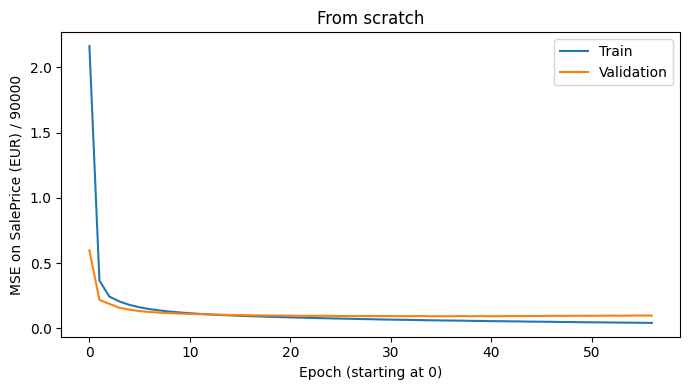

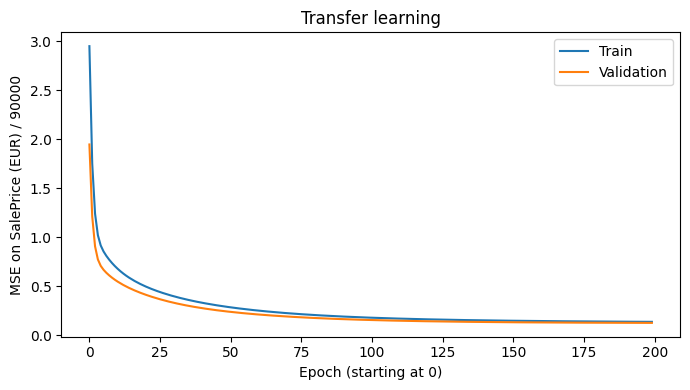

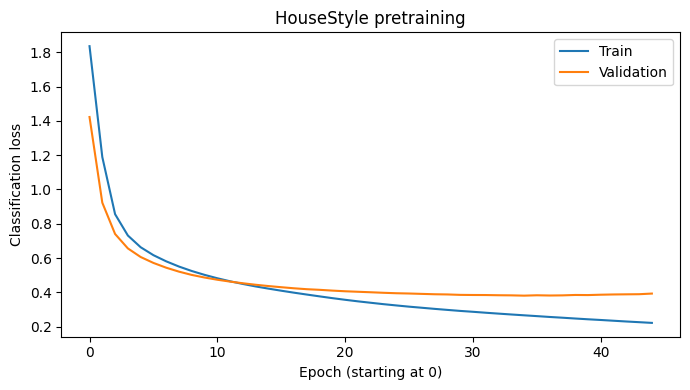

In [10]:
histories = {"From scratch": direct_history, "Transfer learning": transfer_history}

for name, history in histories.items():
    plt.figure(figsize=(7, 4))
    plt.plot(history.history["loss"], label="Train")
    plt.plot(history.history["val_loss"], label="Validation")
    plt.title(name)
    plt.xlabel("Epoch (starting at 0)")
    plt.ylabel("MSE on SalePrice (EUR) / 90000")
    plt.legend()
    plt.tight_layout()
    plt.savefig(results_dir / f"loss_{name}.png")
    plt.show()

plt.figure(figsize=(7, 4))
plt.plot(source_history.history["loss"], label="Train")
plt.plot(source_history.history["val_loss"], label="Validation")
plt.title("HouseStyle pretraining")
plt.xlabel("Epoch (starting at 0)")
plt.ylabel("Classification loss")
plt.legend()
plt.tight_layout()
plt.savefig(results_dir / "pretraining_loss.png")
plt.show()

### 11. Προβλέπουμε τις τιμές και υπολογίζουμε τις μετρικές

Χρησιμοποιούμε τώρα το τελικό test, το οποίο κρατήσαμε έξω από την εκπαίδευση
και την επιλογή της καλύτερης εποχής. Με το predict παίρνουμε τις προβλέψεις,
με το flatten τις μετατρέπουμε σε απλή λίστα αριθμών και πολλαπλασιάζουμε
με το price_scale (90.000) για να πάρουμε τιμές σε ευρώ.

Υπολογίζουμε για τα ίδια σπίτια και στα δύο μοντέλα:

- **MAE:** μετράμε πόσα ευρώ απέχουμε από την πραγματική τιμή κατά μέσο όρο,
  χωρίς να μας ενδιαφέρει αν προβλέψαμε μεγαλύτερη ή μικρότερη τιμή.
- **MAPE:** μετράμε το μέσο απόλυτο σφάλμα ως ποσοστό της πραγματικής τιμής.
  Πολλαπλασιάζουμε την τιμή της βιβλιοθήκης με 100 για ποσοστό. Στο dataset
  έχουμε θετικά SalePrice, επομένως δεν διαιρούμε με μηδέν.
- **RMSE:** παίρνουμε την τετραγωνική ρίζα του MSE. Το μετράμε σε ευρώ και
  επηρεαζόμαστε περισσότερο από τις πολύ μεγάλες αστοχίες.

Προτιμάμε μικρότερες τιμές και στις τρεις μετρικές. Με το for επαναλαμβάνουμε
τον ίδιο υπολογισμό για τα δύο μοντέλα. Κρατάμε τα αποτελέσματα στη λίστα scores
και τα εμφανίζουμε ως σύντομο κείμενο, χωρίς πίνακες δεδομένων.

Μετατρέπουμε με την ίδια ισοτιμία πραγματικές τιμές και προβλέψεις.
Επομένως τα MAE και RMSE σε ευρώ είναι το 90% των αντίστοιχων σφαλμάτων
σε δολάρια. Το MAPE παραμένει το ίδιο, γιατί μετράμε σχετικό σφάλμα.

In [11]:
direct_predictions = direct_model.predict(X_test, verbose=0).flatten() * price_scale
transfer_predictions = transfer_model.predict(X_test, verbose=0).flatten() * price_scale
predictions = {"From scratch": direct_predictions, "Transfer learning": transfer_predictions}
scores = []

for name, predicted in predictions.items():
    mae = mean_absolute_error(y_test, predicted)
    mape = mean_absolute_percentage_error(y_test, predicted) * 100
    rmse = np.sqrt(mean_squared_error(y_test, predicted))
    scores.append([name, mae, mape, rmse])
    print(name)
    print("MAE (€):", round(mae, 2))
    print("MAPE (%):", round(mape, 2))
    print("RMSE (€):", round(rmse, 2))
    print()

From scratch
MAE (€): 18746.64
MAPE (%): 12.0
RMSE (€): 33142.11

Transfer learning
MAE (€): 24500.07
MAPE (%): 16.42
RMSE (€): 49834.76



### 12. Συγκρίνουμε πραγματικές και προβλεπόμενες τιμές

Στον οριζόντιο άξονα βάζουμε την πραγματική τιμή και στον κατακόρυφο την
πρόβλεψή μας. Κάθε σημείο αντιστοιχεί σε ένα σπίτι του test. Στη διακεκομμένη
γραμμή έχουμε τέλεια πρόβλεψη, επειδή πραγματική και προβλεπόμενη τιμή συμπίπτουν.

Πάνω από τη γραμμή υπερεκτιμούμε την τιμή και κάτω από αυτήν την υποεκτιμούμε.
Κρατάμε τα ίδια όρια αξόνων στα δύο γραφήματα, ώστε να συγκρίνουμε τα λάθη
χωρίς να μας παραπλανούν διαφορετικές κλίμακες.

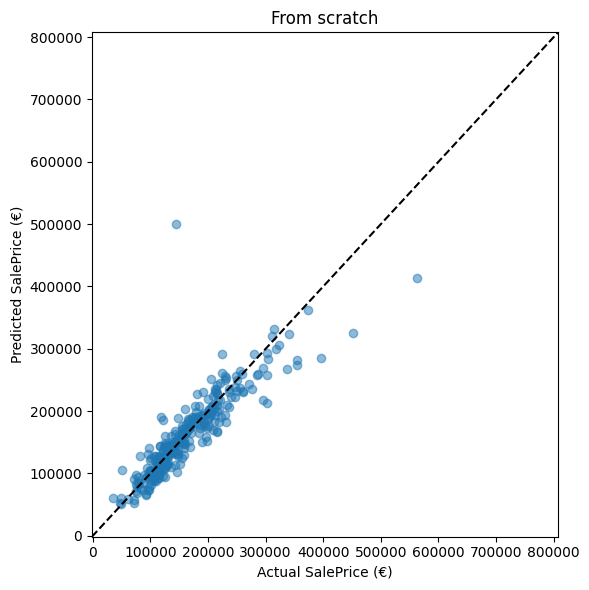

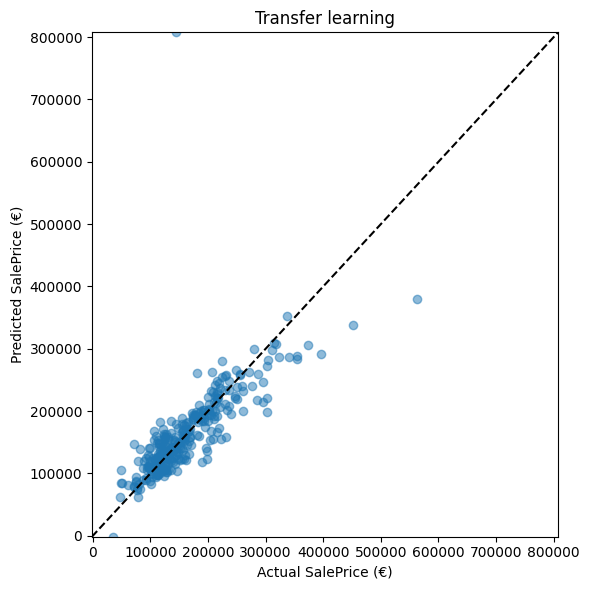

In [12]:
low = min(y_test.min(), direct_predictions.min(), transfer_predictions.min())
high = max(y_test.max(), direct_predictions.max(), transfer_predictions.max())

for name, predicted in predictions.items():
    plt.figure(figsize=(6, 6))
    plt.scatter(y_test, predicted, alpha=0.5)
    plt.plot([low, high], [low, high], "k--")
    plt.xlim(low, high)
    plt.ylim(low, high)
    plt.title(name)
    plt.xlabel("Actual SalePrice (€)")
    plt.ylabel("Predicted SalePrice (€)")
    plt.tight_layout()
    plt.savefig(results_dir / f"predictions_{name}.png")
    plt.show()

### 13. Αποθηκεύουμε τη σύγκριση

Οργανώνουμε τις μετρικές σε ένα DataFrame για να τις αποθηκεύσουμε σε CSV,
χωρίς να εμφανίσουμε τον πίνακα στο notebook. Σχεδιάζουμε χωριστό γράφημα για
κάθε μετρική, επειδή το MAPE είναι ποσοστό ενώ τα MAE και RMSE είναι ευρώ.

Αποθηκεύουμε επίσης την πορεία εκπαίδευσης σε CSV. Έτσι μπορούμε να χρησιμοποιήσουμε
τα γραφήματα και τις μετρικές στην τεχνική αναφορά. Δεν αποθηκεύουμε αντίγραφα
των δεδομένων ή των κατοικιών του test στα αποτελέσματα.

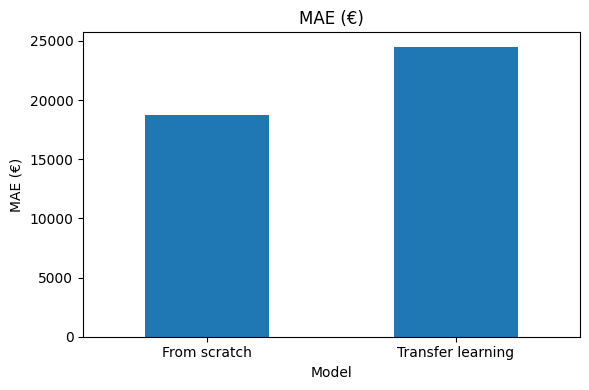

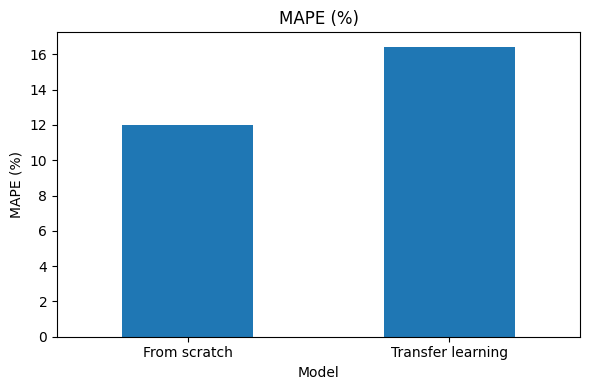

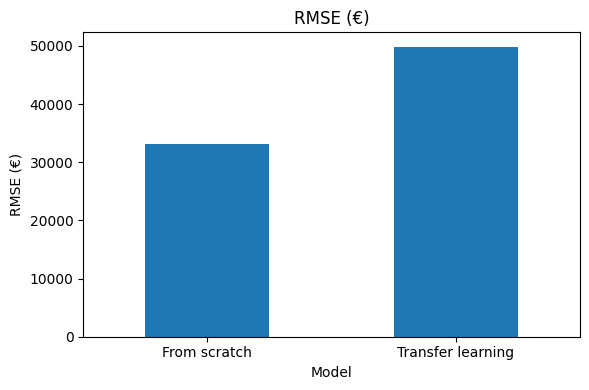

In [13]:
comparison = pd.DataFrame(scores, columns=["Model", "MAE (€)", "MAPE (%)", "RMSE (€)"])
comparison = comparison.set_index("Model")
comparison.to_csv(results_dir / "regression_metrics.csv")

for metric in comparison.columns:
    comparison[metric].plot(kind="bar", figsize=(6, 4))
    plt.title(metric)
    plt.ylabel(metric)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(results_dir / f"comparison_{metric.split()[0]}.png")
    plt.show()

for name, history in histories.items():
    pd.DataFrame(history.history).to_csv(results_dir / f"history_{name}.csv", index=False)
pd.DataFrame(source_history.history).to_csv(results_dir / "history_pretraining.csv", index=False)

### 14. Τι συμπεραίνουμε από αυτή την εκτέλεση

Χρησιμοποιήσαμε 876 κατοικίες για εκπαίδευση, 292 για validation και 292 για
την τελική αξιολόγηση. Με το **δίκτυο από την αρχή** πετύχαμε MAE περίπου
**18.746,64 ευρώ**, MAPE **12,00%** και RMSE **33.142,11 ευρώ**.
Με το **transfer learning** πετύχαμε MAE περίπου **24.500,07 ευρώ**,
MAPE **16,42%** και RMSE **49.834,76 ευρώ**.

Βρίσκουμε μικρότερο σφάλμα στο μοντέλο από την αρχή και στις τρεις μετρικές.
Στη συγκεκριμένη δοκιμή, επομένως, δεν βελτιώσαμε την πρόβλεψη με τη μεταφορά
της βάσης HouseStyle. Παρότι πετύχαμε περίπου 87,7% accuracy στο validation
της προεκπαίδευσης, δεν συμπεραίνουμε ότι αυτή η βάση περιέχει όλη την πληροφορία
που χρειαζόμαστε για την τιμή. Στο transfer κρατήσαμε τη βάση παγωμένη και
εκπαιδεύσαμε μόνο τη νέα έξοδο, ενώ στο πρώτο δίκτυο προσαρμόσαμε όλα τα βάρη
απευθείας στο SalePrice.

Στο πρώτο δίκτυο σταματήσαμε μετά από 57 εποχές και κρατήσαμε τα βάρη της
37ης, όπου είχαμε το μικρότερο validation loss. Παρατηρούμε ότι στη συνέχεια
το training loss μειώνεται χωρίς αντίστοιχο όφελος στο validation.
Στο transfer ολοκληρώσαμε το όριο των 200 εποχών, με καλύτερη την τελευταία.
Δεν ισχυριζόμαστε ότι εξαντλήσαμε κάθε δυνατότητα βελτίωσης ή ότι το μοντέλο
έχει οπωσδήποτε συγκλίνει. Συγκρίνουμε τις συγκεκριμένες ρυθμίσεις που ορίσαμε
πριν εξετάσουμε το test.

Στα γραφήματα προβλέψεων βλέπουμε αρκετά σημεία κοντά στη διαγώνιο, αλλά και
μεγάλες αστοχίες σε ορισμένες κατοικίες. Βρίσκουμε RMSE αρκετά μεγαλύτερο από
MAE, επειδή τα μεγάλα λάθη επηρεάζουν περισσότερο το RMSE. Στο transfer έχουμε
και μία αρνητική πρόβλεψη, που δεν αποτελεί ρεαλιστική τιμή κατοικίας. Με τη
γραμμική έξοδο Dense(1) δεν επιβάλλουμε θετικές τιμές. Κρατάμε και αυτή την
αστοχία στον υπολογισμό των μετρικών, ώστε να παρουσιάσουμε την πραγματική
επίδοση του μοντέλου, και την αναγνωρίζουμε ως περιορισμό.

Δεν γενικεύουμε ότι το transfer learning είναι πάντα χειρότερο. Δοκιμάσαμε
έναν στόχο προεκπαίδευσης, μια παγωμένη βάση και έναν διαχωρισμό δεδομένων.
Αν αλλάξουμε δεδομένα, εκδόσεις ή ρυθμίσεις, ελέγχουμε ξανά και ενημερώνουμε
τα αριθμητικά συμπεράσματα. Στην αναφορά PDF συμπεριλαμβάνουμε τις μετρικές,
τις καμπύλες εκπαίδευσης και τα γραφήματα προβλέψεων μαζί με την ερμηνεία μας.
